In [1]:
%pip install earthengine-api

   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    --------------------------------------- 0.3/17.1 MB ? eta -:--:--
    ----------------

In [1]:
import ee

print("Earth Engine package is working!")
print("Version:", ee.__version__)

Earth Engine package is working!
Version: 1.7.52


In [2]:
import requests

# Le Morne study area
le_morne_aoi = [57.29, -20.48, 57.36, -20.43]

# Copernicus Sentinel-2 catalogue
url = "https://stac.dataspace.copernicus.eu/v1/search"

search = {
    "collections": ["sentinel-2-l2a"],
    "bbox": le_morne_aoi,
    "datetime": "2025-10-01T00:00:00Z/2025-10-31T23:59:59Z",
    "limit": 100
}

response = requests.post(url, json=search)
response.raise_for_status()

data = response.json()
items = data["features"]

print("Number of Sentinel-2 images found:", len(items))

for item in items:
    properties = item["properties"]
    print(
        "Date:", properties.get("datetime"),
        "| Cloud cover:", properties.get("eo:cloud_cover"),
        "| ID:", item["id"]
    )

Number of Sentinel-2 images found: 6
Date: 2025-10-29T06:24:49.024000Z | Cloud cover: 28.06 | ID: S2B_MSIL2A_20251029T062449_N0511_R091_T40KEC_20251029T094311
Date: 2025-10-24T06:25:01.025000Z | Cloud cover: 28.51 | ID: S2C_MSIL2A_20251024T062501_N0511_R091_T40KEC_20251024T083116
Date: 2025-10-19T06:24:49.024000Z | Cloud cover: 18.61 | ID: S2B_MSIL2A_20251019T062449_N0511_R091_T40KEC_20251019T075817
Date: 2025-10-14T06:25:01.025000Z | Cloud cover: 7.96 | ID: S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314
Date: 2025-10-09T06:24:49.024000Z | Cloud cover: 11.4 | ID: S2B_MSIL2A_20251009T062449_N0511_R091_T40KEC_20251009T080600
Date: 2025-10-04T06:25:01.025000Z | Cloud cover: 13.13 | ID: S2C_MSIL2A_20251004T062501_N0511_R091_T40KEC_20251004T083617


In [3]:
selected = next(
    item for item in items
    if item["properties"]["datetime"].startswith("2025-10-14")
)

print("Selected image:", selected["id"])
print("Date:", selected["properties"]["datetime"])
print("Cloud cover:", selected["properties"]["eo:cloud_cover"], "%")

Selected image: S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314
Date: 2025-10-14T06:25:01.025000Z
Cloud cover: 7.96 %


In [4]:
print("Available image bands:")
for band, details in selected["assets"].items():
    print(band, ":", details.get("href"))

Available image bands:
AOT_10m : s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R10m/T40KEC_20251014T062501_AOT_10m.jp2
AOT_20m : s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R20m/T40KEC_20251014T062501_AOT_20m.jp2
AOT_60m : s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R60m/T40KEC_20251014T062501_AOT_60m.jp2
B01_20m : s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R20m/T40KEC_20251014T062501_B01_20m.jp2
B01_60m : s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_

In [5]:
# Show only the Sentinel-2 bands we need
for band in ["B02_10m", "B03_10m", "B04_10m", "B08_10m"]:
    if band in selected["assets"]:
        print(band)
        print(selected["assets"][band]["href"])
        print()

B02_10m
s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R10m/T40KEC_20251014T062501_B02_10m.jp2

B03_10m
s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R10m/T40KEC_20251014T062501_B03_10m.jp2

B04_10m
s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R10m/T40KEC_20251014T062501_B04_10m.jp2

B08_10m
s3://eodata/Sentinel-2/MSI/L2A/2025/10/14/S2C_MSIL2A_20251014T062501_N0511_R091_T40KEC_20251014T083314.SAFE/GRANULE/L2A_T40KEC_A005781_20251014T062458/IMG_DATA/R10m/T40KEC_20251014T062501_B08_10m.jp2



In [8]:
%pip install earthaccess

  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)
   ---------------------------------------- 0.0/16.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.1 MB ? eta -:--:--
    --------------------------------------- 0.3/16.1 MB ? eta -:--:--
    --------------------------------------- 0.3/16.1 MB ? eta -:--:--
    --------------------------------------- 0.3/16.1 MB ? eta -:--:--
    --------------------------------------- 0.3/16.1 MB ? eta -:--:--
    --------------------------------------- 0.3/16.1 MB ? eta -:--:--
    --------------------------------------- 0.3/16.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/16.1 MB 180.4 kB/s eta 0:01:27
   - -------------------------------------- 0.5/16.1 MB 180.4 kB/s eta 0:01:27
   - -----------------

In [11]:
import earthaccess

# Connect to NASA Earthdata
auth = earthaccess.login()

# Search NASA HLS Sentinel-2 data
hls_results = earthaccess.search_data(
    short_name="HLSS30",
    version="2.0",
    bounding_box=(57.29, -20.48, 57.36, -20.43),
    temporal=("2025-10-14", "2025-10-15"),
    count=100
)

print("NASA HLS images found:", len(hls_results))

if hls_results:
    print("\nFirst matching result:")
    print(hls_results[0])

NASA HLS images found: 1

First matching result:
Collection: {'EntryTitle': 'HLS Sentinel-2 Multi-spectral Instrument Surface Reflectance Daily Global 30m v2.0'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': 57.67763469, 'Latitude': -20.88672623}, {'Longitude': 58.05544745, 'Latitude': -20.88481164}, {'Longitude': 58.04871606, 'Latitude': -19.89279541}, {'Longitude': 56.99980893, 'Latitude': -19.89588492}, {'Longitude': 56.99980788, 'Latitude': -20.75253134}, {'Longitude': 57.67763469, 'Latitude': -20.88672623}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2025-10-14T06:25:15.411Z', 'EndingDateTime': '2025-10-14T06:25:15.411Z'}}
Size(MB): 186.26770210266113
Data: ['https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T40KEC.2025287T062501.v2.0/HLS.S30.T40KEC.2025287T062501.v2.0.B12.tif', 'https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSS30.020/HLS.S30.T40

In [2]:
import earthaccess
from pathlib import Path

auth = earthaccess.login()

In [4]:
import earthaccess

auth = earthaccess.login()

hls_results = earthaccess.search_data(
    short_name="HLSS30",
    version="2.0",
    bounding_box=(57.29, -20.48, 57.36, -20.43),
    temporal=("2025-10-14", "2025-10-15"),
    count=100
)

print("Number of granules found:", len(hls_results))


Number of granules found: 1


In [5]:
from pathlib import Path

download_dir = Path("NASA_HLS_LeMorne")
download_dir.mkdir(exist_ok=True)

downloaded_files = earthaccess.download(
    [hls_results[0]],
    local_path=str(download_dir)
)

print("Download completed!")
for file in downloaded_files:
    print(file)

QUEUEING TASKS | :   0%|          | 0/18 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/18 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/18 [00:00<?, ?it/s]

Download completed!
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B12.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.SAA.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B08.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B06.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B04.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B07.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.VAA.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.VZA.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B10.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B8A.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B05.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B11.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.Fmask.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B02.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B09.tif
NASA_HLS_LeMorne\HLS.S30.T40KEC.2025287T062501.v2.0.B01.tif
NASA_HLS_LeMorne\H

In [6]:
from pathlib import Path
import rasterio

data_dir = Path("NASA_HLS_LeMorne")

for file in sorted(data_dir.glob("*.tif")):
    with rasterio.open(file) as src:
        print(
            file.name,
            "| CRS:", src.crs,
            "| Resolution:", src.res,
            "| Shape:", src.shape,
            "| NoData:", src.nodata
        )

HLS.S30.T40KEC.2025287T062501.v2.0.B01.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 3660) | NoData: -9999.0
HLS.S30.T40KEC.2025287T062501.v2.0.B02.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 3660) | NoData: -9999.0
HLS.S30.T40KEC.2025287T062501.v2.0.B03.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 3660) | NoData: -9999.0
HLS.S30.T40KEC.2025287T062501.v2.0.B04.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 3660) | NoData: -9999.0
HLS.S30.T40KEC.2025287T062501.v2.0.B05.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 3660) | NoData: -9999.0
HLS.S30.T40KEC.2025287T062501.v2.0.B06.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 3660) | NoData: -9999.0
HLS.S30.T40KEC.2025287T062501.v2.0.B07.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 3660) | NoData: -9999.0
HLS.S30.T40KEC.2025287T062501.v2.0.B08.tif | CRS: EPSG:32640 | Resolution: (30.0, 30.0) | Shape: (3660, 

In [7]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("NASA_HLS_LeMorne")

# Locate the bands
b03_file = next(data_dir.glob("*.B03.tif"))
b08_file = next(data_dir.glob("*.B08.tif"))
fmask_file = next(data_dir.glob("*.Fmask.tif"))

# Read Green band
with rasterio.open(b03_file) as src:
    green = src.read(1).astype("float32")
    profile = src.profile.copy()

# Read NIR band
with rasterio.open(b08_file) as src:
    nir = src.read(1).astype("float32")

# Read Fmask
with rasterio.open(fmask_file) as src:
    fmask = src.read(1)

# Valid pixels: exclude NoData
valid = (
    (green != -9999) &
    (nir != -9999)
)

# Exclude cloud, cloud shadow and other invalid pixels
# HLS Fmask bits: cloud=1, adjacent cloud=2,
# cloud shadow=3, snow/ice=4
cloud = (
    ((fmask & (1 << 1)) != 0) |
    ((fmask & (1 << 2)) != 0) |
    ((fmask & (1 << 3)) != 0) |
    ((fmask & (1 << 4)) != 0)
)

valid = valid & (~cloud)

# Calculate NDWI
ndwi = np.full(green.shape, np.nan, dtype="float32")

denominator = green + nir

valid = valid & (denominator != 0)

ndwi[valid] = (
    (green[valid] - nir[valid]) /
    denominator[valid]
)

print("NDWI calculated.")
print("Valid pixels:", np.count_nonzero(np.isfinite(ndwi)))

NDWI calculated.
Valid pixels: 10563449


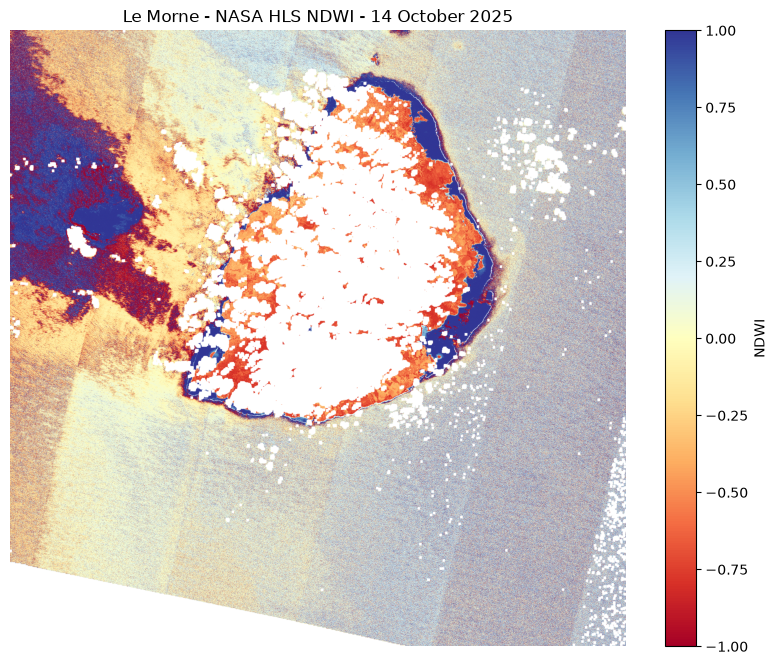

In [8]:
plt.figure(figsize=(10, 8))

plt.imshow(ndwi, cmap="RdYlBu", vmin=-1, vmax=1)

plt.colorbar(label="NDWI")
plt.title("Le Morne - NASA HLS NDWI - 14 October 2025")
plt.axis("off")

plt.show()

Cropped dimensions: (185, 244)


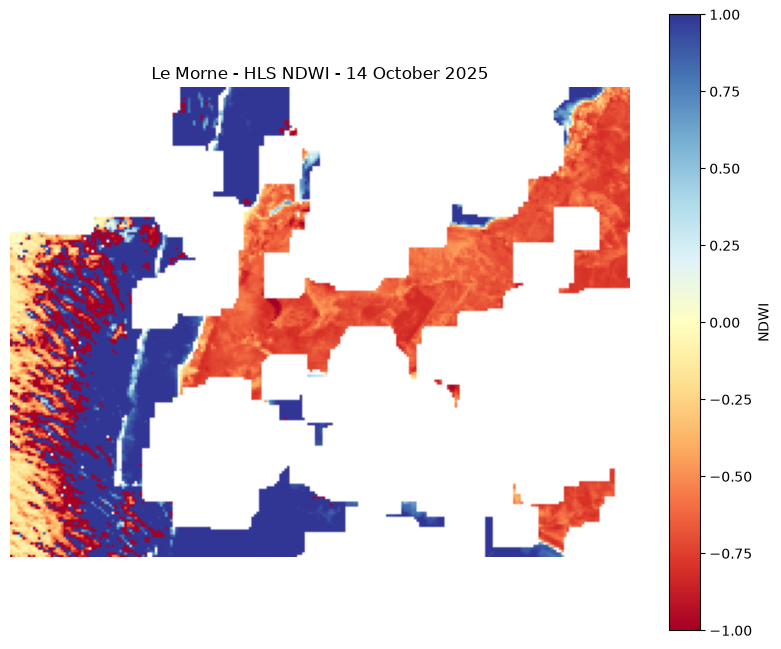

In [10]:
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
le_morne_aoi = [57.29, -20.48, 57.36, -20.43]
# Transform Le Morne AOI into HLS projected CRS
with rasterio.open(b03_file) as src:

    aoi_projected = transform_bounds(
        "EPSG:4326",
        src.crs,
        *le_morne_aoi
    )

    window = from_bounds(
        *aoi_projected,
        transform=src.transform
    )

    window = window.round_offsets().round_lengths()

    ndwi_crop = ndwi[
        int(window.row_off):int(window.row_off + window.height),
        int(window.col_off):int(window.col_off + window.width)
    ]

print("Cropped dimensions:", ndwi_crop.shape)

plt.figure(figsize=(10, 8))
plt.imshow(ndwi_crop, cmap="RdYlBu", vmin=-1, vmax=1)
plt.colorbar(label="NDWI")
plt.title("Le Morne - HLS NDWI - 14 October 2025")
plt.axis("off")
plt.show()

In [11]:
import numpy as np
import rasterio

with rasterio.open(fmask_file) as src:
    fmask_data = src.read(1)

values, counts = np.unique(fmask_data, return_counts=True)

print("Fmask values and pixel counts:")

for value, count in zip(values, counts):
    print(value, ":", count)

Fmask values and pixel counts:
64 : 74533
66 : 184956
68 : 19665
70 : 210
72 : 2280
74 : 14
76 : 975
78 : 6
80 : 1382
84 : 15
96 : 80686
100 : 6
112 : 837
116 : 2
128 : 237448
130 : 208032
132 : 103149
134 : 4025
136 : 26997
138 : 582
140 : 8000
142 : 98
144 : 1891
148 : 25
160 : 925084
164 : 2686
176 : 2974
180 : 18
192 : 198604
194 : 901975
196 : 430021
198 : 68630
200 : 129460
202 : 32072
204 : 17552
206 : 1602
208 : 1551
212 : 54
224 : 9076592
228 : 43763
240 : 4720
244 : 40
255 : 602388


In [12]:
# Correct HLS quality mask

cloud = (
    ((fmask_data & (1 << 1)) != 0) |
    ((fmask_data & (1 << 2)) != 0) |
    ((fmask_data & (1 << 3)) != 0) |
    ((fmask_data & (1 << 4)) != 0)
)

# Exclude NoData pixels as well
nodata = (fmask_data == 255)

# Valid pixels
valid_hls = (~cloud) & (~nodata)

# Also exclude invalid reflectance values
valid_hls &= (green != -9999) & (nir != -9999)

print("Total pixels:", fmask_data.size)
print("Cloud/shadow/snow pixels:", np.count_nonzero(cloud))
print("NoData pixels:", np.count_nonzero(nodata))
print("Valid pixels:", np.count_nonzero(valid_hls))

Total pixels: 13395600
Cloud/shadow/snow pixels: 2802653
NoData pixels: 602388
Valid pixels: 10592947


In [13]:
ndwi = np.full(green.shape, np.nan, dtype="float32")

denominator = green + nir

valid_hls &= (denominator != 0)

ndwi[valid_hls] = (
    (green[valid_hls] - nir[valid_hls]) /
    denominator[valid_hls]
)

Cropped dimensions: (185, 244)
Valid pixels: 17655
Total AOI pixels: 45140
Valid coverage: 39.11 %


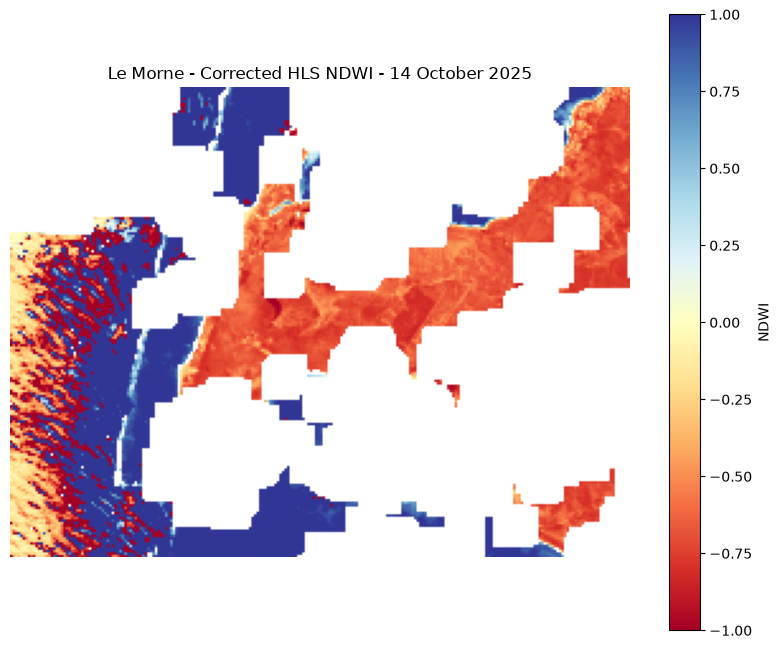

In [14]:
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

le_morne_aoi = [57.29, -20.48, 57.36, -20.43]

with rasterio.open(b03_file) as src:

    aoi_projected = transform_bounds(
        "EPSG:4326",
        src.crs,
        *le_morne_aoi
    )

    window = from_bounds(
        *aoi_projected,
        transform=src.transform
    ).round_offsets().round_lengths()

    ndwi_crop = ndwi[
        int(window.row_off):int(window.row_off + window.height),
        int(window.col_off):int(window.col_off + window.width)
    ]

    valid_crop = valid_hls[
        int(window.row_off):int(window.row_off + window.height),
        int(window.col_off):int(window.col_off + window.width)
    ]

print("Cropped dimensions:", ndwi_crop.shape)
print("Valid pixels:", np.count_nonzero(valid_crop))
print("Total AOI pixels:", valid_crop.size)
print("Valid coverage:", round(100 * valid_crop.mean(), 2), "%")

plt.figure(figsize=(10, 8))
plt.imshow(ndwi_crop, cmap="RdYlBu", vmin=-1, vmax=1)
plt.colorbar(label="NDWI")
plt.title("Le Morne - Corrected HLS NDWI - 14 October 2025")
plt.axis("off")
plt.show()

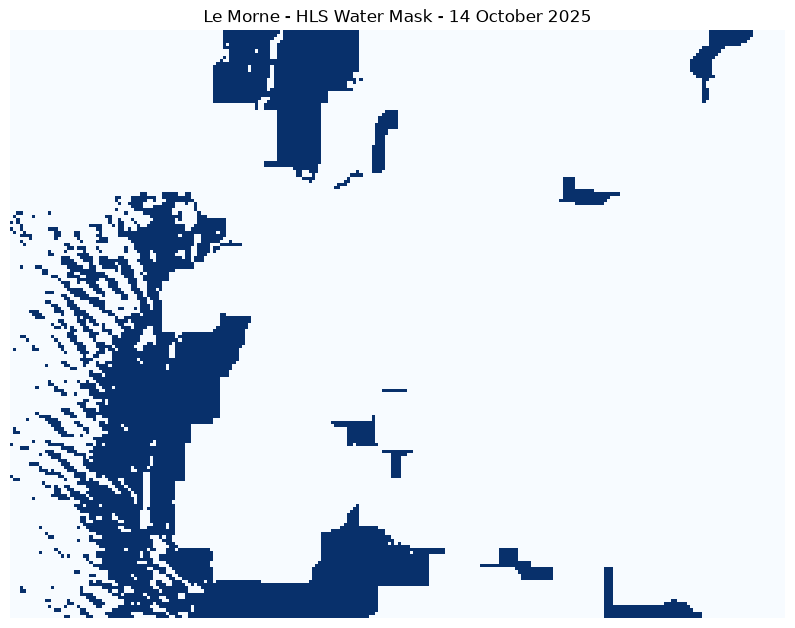

Water pixels: 7198


In [15]:
water_mask = (
    (ndwi_crop > 0) &
    np.isfinite(ndwi_crop)
)

plt.figure(figsize=(10, 8))
plt.imshow(water_mask, cmap="Blues")
plt.title("Le Morne - HLS Water Mask - 14 October 2025")
plt.axis("off")
plt.show()

print("Water pixels:", np.count_nonzero(water_mask))

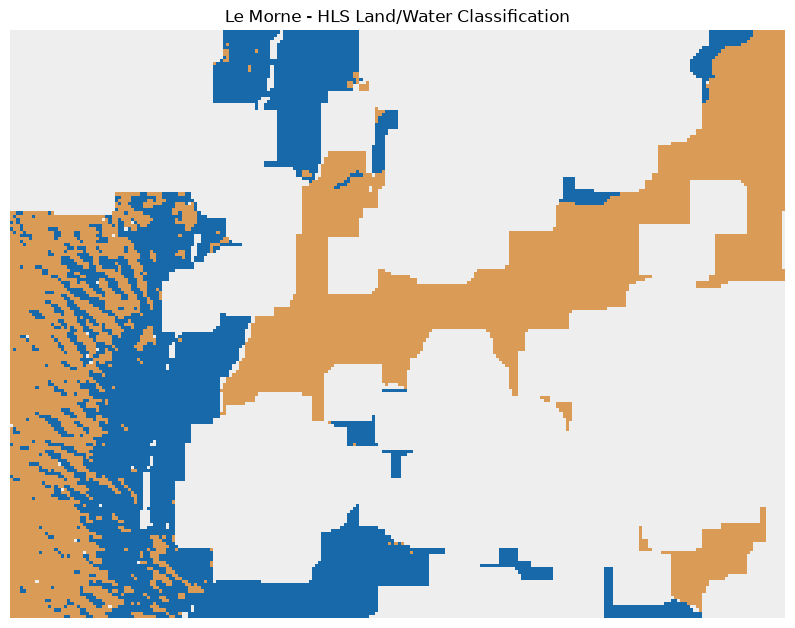

Land pixels: 10457
Water pixels: 7198
Invalid pixels: 27485


In [16]:
import matplotlib.colors as mcolors

land_mask = (
    (ndwi_crop <= 0) &
    np.isfinite(ndwi_crop)
)

water_mask = (
    (ndwi_crop > 0) &
    np.isfinite(ndwi_crop)
)

invalid_mask = ~np.isfinite(ndwi_crop)

classified = np.full(ndwi_crop.shape, 2)

classified[land_mask] = 0
classified[water_mask] = 1

cmap = mcolors.ListedColormap([
    "#d99b55",  # Land
    "#1769aa",  # Water
    "#eeeeee"   # Invalid
])

plt.figure(figsize=(10, 8))
plt.imshow(classified, cmap=cmap, vmin=0, vmax=2)

plt.title("Le Morne - HLS Land/Water Classification")
plt.axis("off")

plt.show()

print("Land pixels:", np.count_nonzero(land_mask))
print("Water pixels:", np.count_nonzero(water_mask))
print("Invalid pixels:", np.count_nonzero(invalid_mask))

In [17]:
import rasterio
import numpy as np
from rasterio.features import shapes
from shapely.geometry import shape, MultiLineString
from shapely.ops import unary_union, transform
from pyproj import Transformer
from pathlib import Path
import json
import matplotlib.pyplot as plt

# Get the cropped raster's actual geographic transform
with rasterio.open(b03_file) as src:
    crop_transform = src.window_transform(window)
    source_crs = src.crs

# Convert land pixels into polygons
land_polygons = [
    shape(geom)
    for geom, value in shapes(
        land_mask.astype("uint8"),
        mask=land_mask,
        transform=crop_transform
    )
    if value == 1
]

# Convert water pixels into polygons
water_polygons = [
    shape(geom)
    for geom, value in shapes(
        water_mask.astype("uint8"),
        mask=water_mask,
        transform=crop_transform
    )
    if value == 1
]

# Merge neighbouring polygons
land_union = unary_union(land_polygons)
water_union = unary_union(water_polygons)

# Extract only shared land-water boundaries
shared_boundary = (
    land_union.boundary.intersection(water_union.boundary)
)

def collect_lines(geometry):
    if geometry.geom_type == "LineString":
        return [geometry]
    elif geometry.geom_type in ("MultiLineString", "GeometryCollection"):
        result = []
        for part in geometry.geoms:
            result.extend(collect_lines(part))
        return result
    return []

shoreline_parts = collect_lines(shared_boundary)

print("Shoreline segments extracted:", len(shoreline_parts))
print("Total shoreline length (m):",
      round(sum(line.length for line in shoreline_parts), 2))

Shoreline segments extracted: 1806
Total shoreline length (m): 73110.0


In [18]:
from shapely.geometry import mapping
from pyproj import Transformer
import json

shoreline = MultiLineString(shoreline_parts)

reproject = Transformer.from_crs(
    source_crs, "EPSG:4326", always_xy=True
)

shoreline_wgs84 = transform(
    reproject.transform, shoreline
)

output_dir = Path("frontend_exports")
output_dir.mkdir(exist_ok=True)

output_file = output_dir / "le_morne_hls_shoreline_2025.geojson"

geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {
            "location": "Le Morne",
            "source": "NASA HLS S30",
            "date": "2025-10-14",
            "method": "NDWI > 0 preliminary classification",
            "resolution_m": 30
        },
        "geometry": mapping(shoreline_wgs84)
    }]
}

with open(output_file, "w") as f:
    json.dump(geojson, f)

print("Exported:", output_file)

Exported: frontend_exports\le_morne_hls_shoreline_2025.geojson


C:\Users\Alexia\AppData\Local\Temp\ipykernel_8808\3431296539.py:11: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  shoreline_wgs84 = transform(


In [19]:
from pathlib import Path

output_dir = Path("frontend_exports")
output_dir.mkdir(exist_ok=True)

plt.savefig(
    output_dir / "le_morne_hls_shoreline_2025.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

Shoreline segments: 1806
Total extracted length: 73110.0 metres


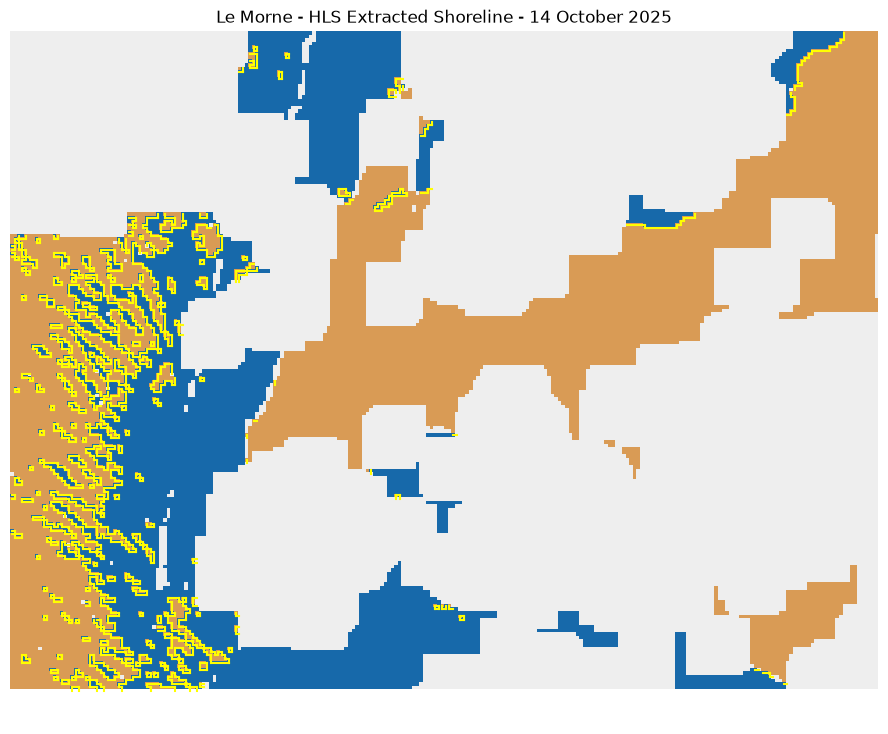

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union
from pathlib import Path

# Get the cropped image's geospatial transform
with rasterio.open(b03_file) as src:
    crop_transform = src.window_transform(window)

# Convert valid land pixels into polygons
land_polygons = [
    shape(geom)
    for geom, value in shapes(
        land_mask.astype("uint8"),
        mask=land_mask,
        transform=crop_transform
    )
    if value == 1
]

# Convert valid water pixels into polygons
water_polygons = [
    shape(geom)
    for geom, value in shapes(
        water_mask.astype("uint8"),
        mask=water_mask,
        transform=crop_transform
    )
    if value == 1
]

# Merge neighbouring polygons
land_union = unary_union(land_polygons)
water_union = unary_union(water_polygons)

# Extract boundaries shared by valid land and water
shared_boundary = land_union.boundary.intersection(
    water_union.boundary
)

# Keep line geometries only
def get_lines(geom):
    if geom.geom_type == "LineString":
        return [geom]
    if hasattr(geom, "geoms"):
        result = []
        for part in geom.geoms:
            result.extend(get_lines(part))
        return result
    return []

shoreline_parts = get_lines(shared_boundary)

print("Shoreline segments:", len(shoreline_parts))
print(
    "Total extracted length:",
    round(sum(line.length for line in shoreline_parts), 2),
    "metres"
)

# Plot the classification and shoreline together
fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(classified, cmap=cmap, vmin=0, vmax=2)

inverse_transform = ~crop_transform

for line in shoreline_parts:
    coords = np.array([
        inverse_transform * (x, y)
        for x, y in line.coords
    ])

    ax.plot(
        coords[:, 0],
        coords[:, 1],
        color="yellow",
        linewidth=1.5
    )

ax.set_title("Le Morne - HLS Extracted Shoreline - 14 October 2025")
ax.axis("off")

# Save the actual plotted result
output_dir = Path("frontend_exports")
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / "le_morne_hls_shoreline_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

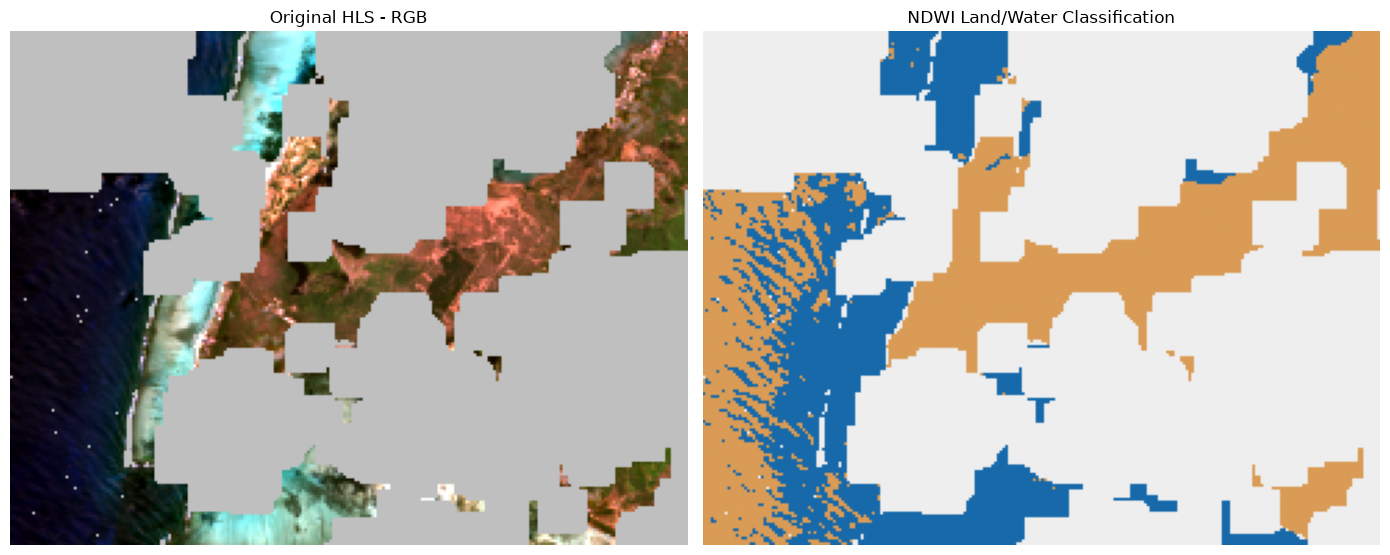

In [21]:
# Locate Sentinel-2 HLS RGB bands
b02_file = next(data_dir.glob("*.B02.tif"))
b04_file = next(data_dir.glob("*.B04.tif"))

# Read cropped RGB bands
with rasterio.open(b02_file) as src:
    blue = src.read(1, window=window).astype("float32")

with rasterio.open(b04_file) as src:
    red = src.read(1, window=window).astype("float32")

with rasterio.open(b03_file) as src:
    green_rgb = src.read(1, window=window).astype("float32")

# Valid RGB pixels
rgb_valid = (
    valid_crop &
    (blue != -9999) &
    (red != -9999) &
    (green_rgb != -9999)
)

# Contrast stretch
def stretch_band(band):
    lo, hi = np.percentile(band[rgb_valid], [2, 98])
    return np.clip((band - lo) / (hi - lo), 0, 1)

rgb = np.dstack([
    stretch_band(red),
    stretch_band(green_rgb),
    stretch_band(blue)
])

rgb[~rgb_valid] = [0.75, 0.75, 0.75]

# Compare
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(rgb)
axes[0].set_title("Original HLS - RGB")
axes[0].axis("off")

axes[1].imshow(classified, cmap=cmap, vmin=0, vmax=2)
axes[1].set_title("NDWI Land/Water Classification")
axes[1].axis("off")

plt.tight_layout()
plt.show()

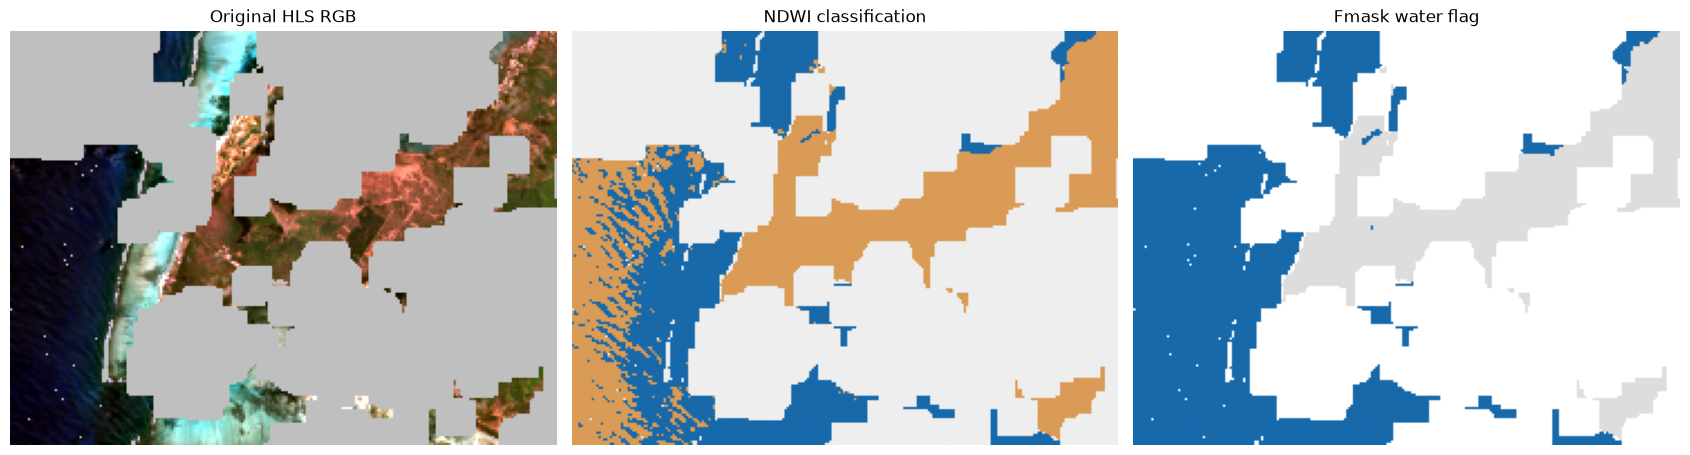

Fmask water pixels: 10917


In [22]:
# Crop Fmask to the same Le Morne AOI
r0 = int(window.row_off)
c0 = int(window.col_off)
r1 = r0 + ndwi_crop.shape[0]
c1 = c0 + ndwi_crop.shape[1]

fmask_crop = fmask_data[r0:r1, c0:c1]

# HLS Fmask bit 5 = water
fmask_water_crop = (
    ((fmask_crop & (1 << 5)) != 0) &
    np.isfinite(ndwi_crop)
)

# Display three comparisons
fig, axes = plt.subplots(1, 3, figsize=(17, 7))

axes[0].imshow(rgb)
axes[0].set_title("Original HLS RGB")

axes[1].imshow(classified, cmap=cmap, vmin=0, vmax=2)
axes[1].set_title("NDWI classification")

fmask_display = np.ma.masked_where(
    ~np.isfinite(ndwi_crop),
    fmask_water_crop.astype(float)
)

axes[2].imshow(
    fmask_display,
    cmap=mcolors.ListedColormap(["#dddddd", "#1769aa"]),
    vmin=0,
    vmax=1
)
axes[2].set_title("Fmask water flag")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(
    "Fmask water pixels:",
    np.count_nonzero(fmask_water_crop)
)

In [23]:
# Compare the two water classifications

ndwi_water = (ndwi_crop > 0) & valid_crop
fmask_water = fmask_water_crop & valid_crop

# Agreement and disagreement
water_agreement = ndwi_water & fmask_water
fmask_only = fmask_water & ~ndwi_water
ndwi_only = ndwi_water & ~fmask_water

print("Both identify water:", np.count_nonzero(water_agreement))
print("Fmask only identifies water:", np.count_nonzero(fmask_only))
print("NDWI only identifies water:", np.count_nonzero(ndwi_only))

Both identify water: 7198
Fmask only identifies water: 3719
NDWI only identifies water: 0


Land pixels: 6738
Water pixels: 10917
Invalid pixels: 27485


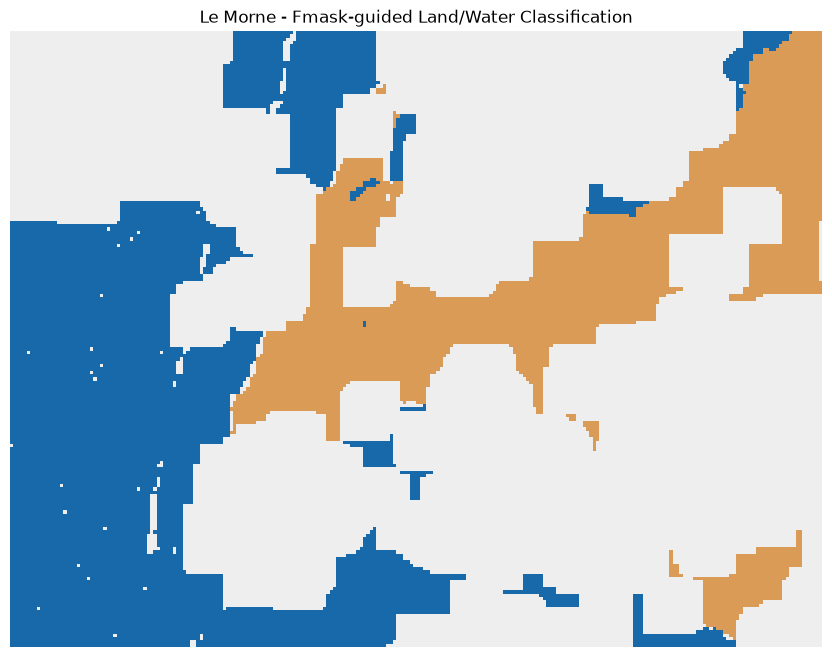

In [24]:
# Fmask-guided land/water classification

water_mask = fmask_water_crop & valid_crop

land_mask = (~fmask_water_crop) & valid_crop

invalid_mask = ~valid_crop

classified = np.full(ndwi_crop.shape, 2, dtype=np.uint8)

classified[land_mask] = 0
classified[water_mask] = 1

print("Land pixels:", np.count_nonzero(land_mask))
print("Water pixels:", np.count_nonzero(water_mask))
print("Invalid pixels:", np.count_nonzero(invalid_mask))

plt.figure(figsize=(11, 8))
plt.imshow(classified, cmap=cmap, vmin=0, vmax=2)
plt.title("Le Morne - Fmask-guided Land/Water Classification")
plt.axis("off")
plt.show()

In [25]:
import cv2
import numpy as np

# Identify connected water regions
water_binary = water_mask.astype(np.uint8)

num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        water_binary,
        connectivity=8
    )
)

water_sizes = stats[1:, cv2.CC_STAT_AREA]

print("Water components:", num_labels - 1)
print("Largest water components:", sorted(
    water_sizes, reverse=True
)[:10])

print("Smallest water components:", sorted(
    water_sizes
)[:10])

Water components: 12
Largest water components: [np.int32(8887), np.int32(1273), np.int32(164), np.int32(164), np.int32(93), np.int32(91), np.int32(90), np.int32(85), np.int32(36), np.int32(23)]
Smallest water components: [np.int32(2), np.int32(9), np.int32(23), np.int32(36), np.int32(85), np.int32(90), np.int32(91), np.int32(93), np.int32(164), np.int32(164)]


Extracted segments: 9
Total shoreline length: 1230.0 m


C:\Users\Alexia\AppData\Local\Temp\ipykernel_8808\1473570826.py:76: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  shoreline_wgs84 = transform(


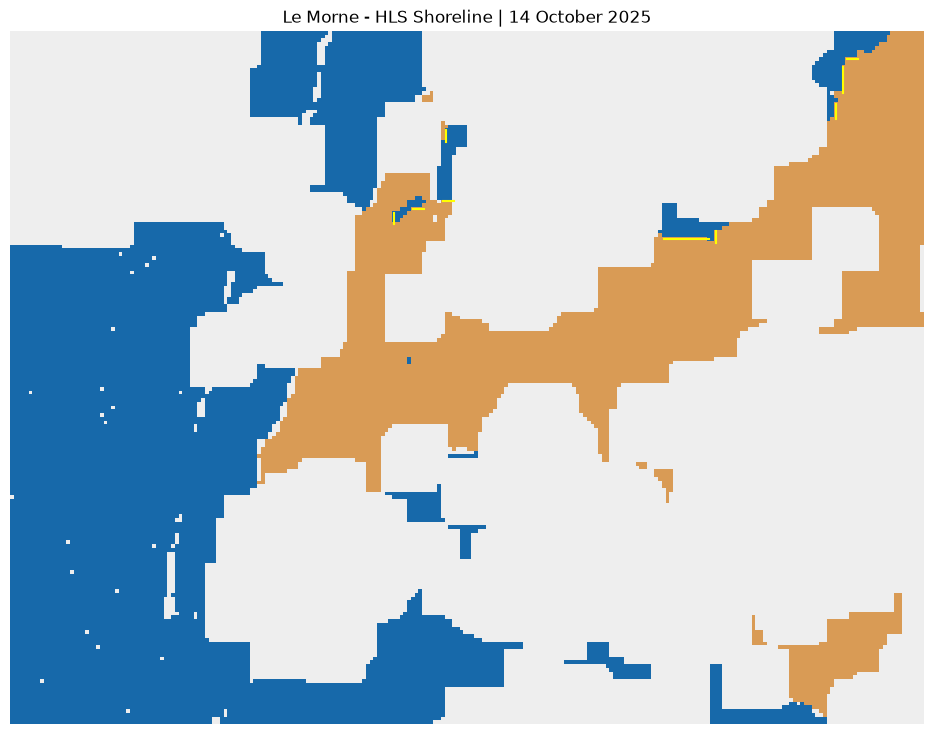


Exports saved in: C:\Users\Alexia\.ipython\frontend_exports


In [26]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.features import shapes
from shapely.geometry import shape, MultiLineString, mapping
from shapely.ops import unary_union, transform
from pyproj import Transformer
from pathlib import Path
import json

# Get georeferencing for the cropped image
with rasterio.open(b03_file) as src:
    crop_transform = src.window_transform(window)
    source_crs = src.crs

# Convert land and water classifications into polygons
land_polygons = [
    shape(geom)
    for geom, value in shapes(
        land_mask.astype("uint8"),
        mask=land_mask,
        transform=crop_transform
    )
    if value == 1
]

water_polygons = [
    shape(geom)
    for geom, value in shapes(
        water_mask.astype("uint8"),
        mask=water_mask,
        transform=crop_transform
    )
    if value == 1
]

# Find shared land-water boundaries
land_union = unary_union(land_polygons)
water_union = unary_union(water_polygons)

boundary = land_union.boundary.intersection(
    water_union.boundary
)

# Collect line segments
def get_lines(geom):
    if geom.geom_type in ("LineString", "LinearRing"):
        return [geom]
    if hasattr(geom, "geoms"):
        lines = []
        for part in geom.geoms:
            lines.extend(get_lines(part))
        return lines
    return []

all_lines = get_lines(boundary)

# Remove tiny fragments: 90 metres = 3 HLS pixels
shoreline_parts = [
    line for line in all_lines
    if line.length >= 90
]

print("Extracted segments:", len(shoreline_parts))
print("Total shoreline length:",
      round(sum(line.length for line in shoreline_parts), 2), "m")

# Combine shoreline
shoreline = MultiLineString(shoreline_parts)

# Convert to latitude/longitude
reproject = Transformer.from_crs(
    source_crs, "EPSG:4326", always_xy=True
)

shoreline_wgs84 = transform(
    reproject.transform, shoreline
)

# Create export folder
output_dir = Path("frontend_exports")
output_dir.mkdir(exist_ok=True)

# Export GeoJSON
geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {
            "location": "Le Morne",
            "source": "NASA HLS S30",
            "date": "2025-10-14",
            "resolution_m": 30,
            "method": "Fmask-guided water classification",
            "minimum_segment_length_m": 90
        },
        "geometry": mapping(shoreline_wgs84)
    }]
}

with open(output_dir / "le_morne_hls_shoreline_2025.geojson", "w") as f:
    json.dump(geojson, f)

# Preview and save PNG
fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(classified, cmap=cmap, vmin=0, vmax=2)

inverse_transform = ~crop_transform

for line in shoreline_parts:
    coords = np.array([
        inverse_transform * (x, y)
        for x, y in line.coords
    ])
    ax.plot(coords[:, 0], coords[:, 1],
            color="yellow", linewidth=1.5)

ax.set_title("Le Morne - HLS Shoreline | 14 October 2025")
ax.axis("off")

fig.savefig(
    output_dir / "le_morne_hls_shoreline_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nExports saved in:", output_dir.resolve())

Shoreline contact pixels: 130


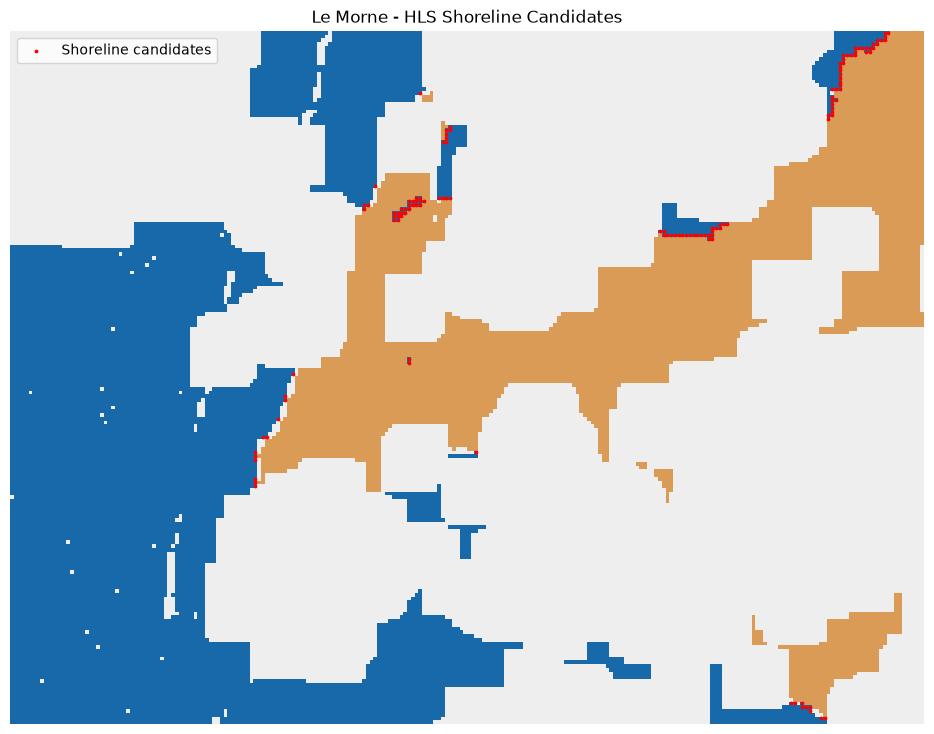

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Find water pixels touching valid land pixels
kernel = np.ones((3, 3), np.uint8)

land_dilated = cv2.dilate(
    land_mask.astype(np.uint8),
    kernel,
    iterations=1
)

shoreline_pixels = (
    water_mask &
    (land_dilated > 0)
)

print("Shoreline contact pixels:",
      np.count_nonzero(shoreline_pixels))

# Display the result
fig, ax = plt.subplots(figsize=(12, 9))

ax.imshow(classified, cmap=cmap, vmin=0, vmax=2)

y, x = np.where(shoreline_pixels)

ax.scatter(x, y, s=3, color="red", label="Shoreline candidates")

ax.set_title("Le Morne - HLS Shoreline Candidates")
ax.axis("off")
ax.legend()

plt.show()